In [2]:
# importing the libraries
import tensorflow
from tensorflow import keras
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras import Sequential

In [4]:
# loading the dataset
(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()

11490434/11490434 [==============================] - 0s 0us/step


In [5]:
# Checking the shape of data
X_train.shape

(60000, 28, 28)

- The data is three dimensional, the first dimension is number of images and 2nd and third dimensions are pixels for each image, it it like containing 2d images 

In [6]:
# starting the model
model = Sequential()

# creating first layer to flatten the image into 28 x 28 = 784 values
model.add(Flatten(input_shape=(28,28)))

# defining the 1st hidden layer
model.add(Dense(100,activation="relu"))

#defining the output layer, using 10 perceptrons as their are 10 classes, using softmax to get the probability for each class
model.add(Dense(10,activation="softmax"))

In [7]:
# getting model summary
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 784)               0         
                                                                 
 dense (Dense)               (None, 100)               78500     
                                                                 
 dense_1 (Dense)             (None, 10)                1010      
                                                                 
Total params: 79,510
Trainable params: 79,510
Non-trainable params: 0
_________________________________________________________________


In [8]:
# compiling the model
model.compile(loss="sparse_categorical_crossentropy",optimizer="Adam",metrics=["accuracy"])

In [9]:
# fitting the model
history = model.fit(X_train,y_train,epochs=20,validation_split=0.2)

Epoch 1/20
1500/1500 [==============================] - 7s 4ms/step - loss: 2.6102 - accuracy: 0.8147 - val_loss: 0.6437 - val_accuracy: 0.8722
Epoch 2/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.4827 - accuracy: 0.8841 - val_loss: 0.3952 - val_accuracy: 0.9078
Epoch 3/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.3450 - accuracy: 0.9133 - val_loss: 0.3240 - val_accuracy: 0.9190
Epoch 4/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.2711 - accuracy: 0.9297 - val_loss: 0.2723 - val_accuracy: 0.9312
Epoch 5/20
1500/1500 [==============================] - 6s 4ms/step - loss: 0.2431 - accuracy: 0.9359 - val_loss: 0.2787 - val_accuracy: 0.9352
Epoch 6/20
1500/1500 [==============================] - 7s 5ms/step - loss: 0.2330 - accuracy: 0.9410 - val_loss: 0.2507 - val_accuracy: 0.9368
Epoch 7/20
1500/1500 [==============================] - 10s 7ms/step - loss: 0.2095 - accuracy: 0.9462 - val_loss: 0.2854 - val_accuracy

In [10]:
import matplotlib.pyplot as plt

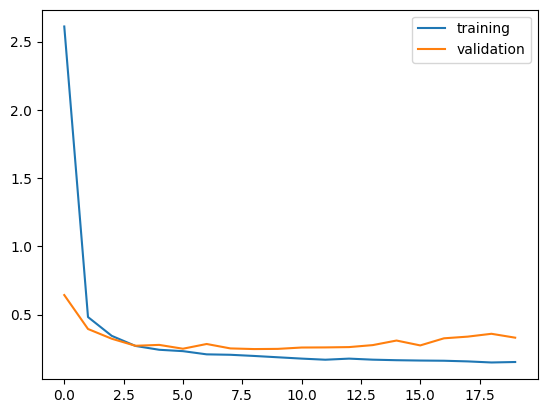

In [12]:
# plotting training and validation set loss
plt.plot(history.history['loss'],label="training")
plt.plot(history.history['val_loss'],label="validation")
plt.legend()

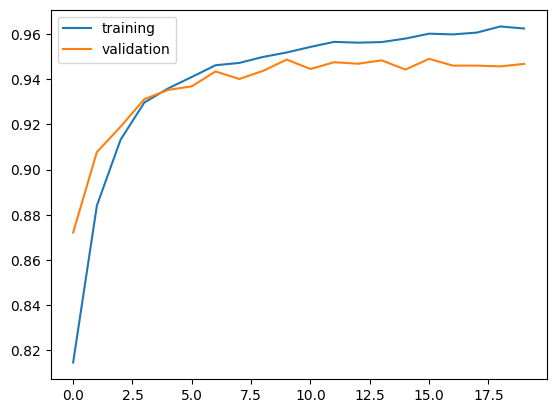

In [13]:
# plotting training and validation set accuracy
plt.plot(history.history['accuracy'],label="training")
plt.plot(history.history['val_accuracy'],label="validation")
plt.legend()

In [14]:
# now prediction on testing set
y_pred_prob = model.predict(X_test)

313/313 [==============================] - 1s 4ms/step


In [16]:
y_pred_prob[0]

array([0.0000000e+00, 3.1546446e-38, 8.3095826e-21, 3.0351873e-34,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 9.9999994e-01,
       0.0000000e+00, 1.6533016e-28], dtype=float32)

- The model is outputting 10 values for one data point, these are the probabilities for the datapoint for all the 10 classes, to extract the labels we can extract the index of each data point probabilities where the probability is the highest as compared to other probabilities for the same data point

In [17]:
import numpy as np
from sklearn.metrics import accuracy_score

In [18]:
# getting the index with top probability value
y_prd = np.argmax(y_pred_prob,axis=1)

In [19]:
accuracy = accuracy_score(y_test,y_prd)

In [20]:
accuracy

0.9452

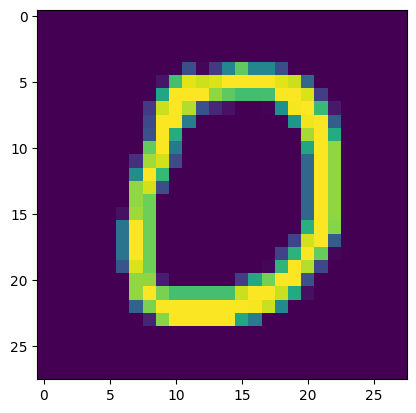

In [21]:
# plotting the original image 
plt.imshow(X_test[10])
plt.show()

- it looks like a zero, let's get the model prediction

In [23]:
test = model.predict(X_test[10].reshape(1,28,28))

1/1 [==============================] - 0s 34ms/step


In [25]:
np.argmax(test,axis=1)

array([0])

- the predicted valu for the data point by the model is zero